# Proyecto Final: Análisis de Ventas y Predicción (Consolidado)
Este cuadernillo unifica todo el pipeline del proyecto:
1. Limpieza y Transformación (Entregable 1)
2. EDA y Visualización (Entregable 2)
3. Clustering con K-Means (Entregable 3)
4. Análisis de Series Temporales y Predicción (Entregable 6)

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
import scipy.stats as stats
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
import scipy.stats as stats
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

ruta = ruta = r"C:\Users\Josue Santana Robled\Downloads"

In [23]:
fact     = pd.read_csv(os.path.join(ruta, "FACT_SALES.csv"))
product  = pd.read_csv(os.path.join(ruta, "DIM_PRODUCT.csv"), encoding="cp1252", dtype={"ITEM": str})
calendar = pd.read_csv(os.path.join(ruta, "DIM_CALENDAR.csv"))
segment  = pd.read_csv(os.path.join(ruta, "DIM_SEGMENT.csv"))
category = pd.read_csv(os.path.join(ruta, "DIM_CATEGORY.csv"))

print("FACT_SALES:", fact.shape)
print("DIM_PRODUCT:", product.shape)
print("DIM_CALENDAR:", calendar.shape)
print("DIM_SEGMENT:", segment.shape)
print("DIM_CATEGORY:", category.shape)

FACT_SALES: (122002, 6)
DIM_PRODUCT: (505, 9)
DIM_CALENDAR: (156, 5)
DIM_SEGMENT: (53, 6)
DIM_CATEGORY: (5, 2)


In [24]:
product = product.map(lambda x: x.strip().upper() if isinstance(x, str) else x)
product = product.fillna('NO DEFINIDO')

segment['ATTR1'] = segment['ATTR1'].str.replace('PRE LAVADOR', 'PRELAVADOR')
segment['ATTR3'] = segment['ATTR3'].str.replace('PRE LAVADOR', 'PRELAVADOR')
segment['ATTR1'] = segment['ATTR1'].str.title()
segment['ATTR2'] = segment['ATTR2'].str.title()
segment['ATTR3'] = segment['ATTR3'].str.title()
segment['FORMAT'] = segment['FORMAT'].str.title()
segment['SEGMENT'] = segment['SEGMENT'].str.title()
segment = segment.dropna()

product['SEGMENT'] = segment['SEGMENT']  
product.loc[(product['FORMAT'] == 'LIQUIDO') | (product['FORMAT'] == 'GEL'), 'SEGMENT'] = 'LIQUID&GEL'
product.loc[(product['ATTR1'] == 'CLORO') | (product['ATTR2'] == 'CLORO'), 'SEGMENT'] = 'BLEACH'
product.loc[product['FORMAT'] == 'POLVO', 'SEGMENT'] = 'Powder'

product.head()

,MANUFACTURER,BRAND,ITEM,ITEM_DESCRIPTION,CATEGORY,FORMAT,ATTR1,ATTR2,ATTR3,SEGMENT
0,INDS. ALEN,CLORALEX,0000075000592,CLORALEX EL RENDIDOR BOT.PLAST. 250ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO,BLEACH
1,INDS. ALEN,CLORALEX,0000075000608,CLORALEX EL RENDIDOR BOT.PLAST. 500ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO,BLEACH
2,INDS. ALEN,CLORALEX,0000075000615,CLORALEX EL RENDIDOR BOT.PLAST. 950ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO,BLEACH
3,INDS. ALEN,CLORALEX,0000075000622,CLORALEX EL RENDIDOR BOT.PLAST. 2000ML NAL 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO,BLEACH
4,INDS. ALEN,CLORALEX,0000075000639,CLORALEX EL RENDIDOR BOT.PLAST. 3750ML NAL 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO,BLEACH


In [25]:
# --- LIMPIEZA FACT_SALES ---
fact["ITEM_CODE"] = fact["ITEM_CODE"].astype(str).str.strip()
fact["WEEK"] = fact["WEEK"].astype(str).str.strip()
fact["TOTAL_UNIT_SALES"] = pd.to_numeric(fact["TOTAL_UNIT_SALES"], errors="coerce")
fact["TOTAL_VALUE_SALES"] = pd.to_numeric(fact["TOTAL_VALUE_SALES"], errors="coerce")
fact = fact.drop_duplicates().fillna(0)

# --- LIMPIEZA DIM_CALENDAR ---
calendar = calendar.rename(columns={'WEEK':'Semana','YEAR':'Año','MONTH':'Mes','WEEK_NUMBER':'Numero_Semana','DATE':'Fecha'})
calendar["Semana"] = calendar["Semana"].astype(str).str.strip()
calendar["Fecha"] = pd.to_datetime(calendar["Fecha"], format='%d/%m/%Y', errors='coerce')
calendar['dia'] = calendar['Fecha'].dt.day
calendar['mes_nombre'] = calendar['Fecha'].dt.month_name()
calendar['dia_semana'] = calendar['Fecha'].dt.day_name()
calendar = calendar.drop_duplicates().fillna('No definido')

# Validación de cruce de semanas
semanas_fact = set(fact["WEEK"].unique())
semanas_cal = set(calendar["Semana"].unique())
print("Semanas en FACT:", len(semanas_fact))
print("Semanas en CALENDAR:", len(semanas_cal))
print("Semanas en FACT sin calendario:", len(semanas_fact - semanas_cal))

Semanas en FACT: 80
Semanas en CALENDAR: 156
Semanas en FACT sin calendario: 0


In [26]:
# Merge principal (Entregable 2)
df = fact.merge(product[["ITEM","MANUFACTURER","BRAND","ITEM_DESCRIPTION","CATEGORY","FORMAT","ATTR1","ATTR2","ATTR3","SEGMENT"]],left_on="ITEM_CODE", right_on="ITEM", how="left")
df = df.merge(calendar[["Semana","Año","Mes","Numero_Semana","Fecha"]], left_on="WEEK", right_on="Semana", how="left")

print("Consolidado:", df.shape)
print("Sin match de producto:", df["BRAND"].isna().sum())
print("Sin match de fecha:", df["Fecha"].isna().sum())
print("Duplicados exactos:", df.duplicated().sum())

# Creación de la columna BRAND_GRUPO (Entregable 6)
df["BRAND"] = df["BRAND"].astype(str).str.upper().str.strip()
df["BRAND_GRUPO"] = np.where(df["BRAND"].str.contains("VANISH"), "VANISH",np.where(df["BRAND"].str.contains("LYSOL"), "LYSOL", df["BRAND"]))

Consolidado: (122002, 21)
Sin match de producto: 0
Sin match de fecha: 0
Duplicados exactos: 0


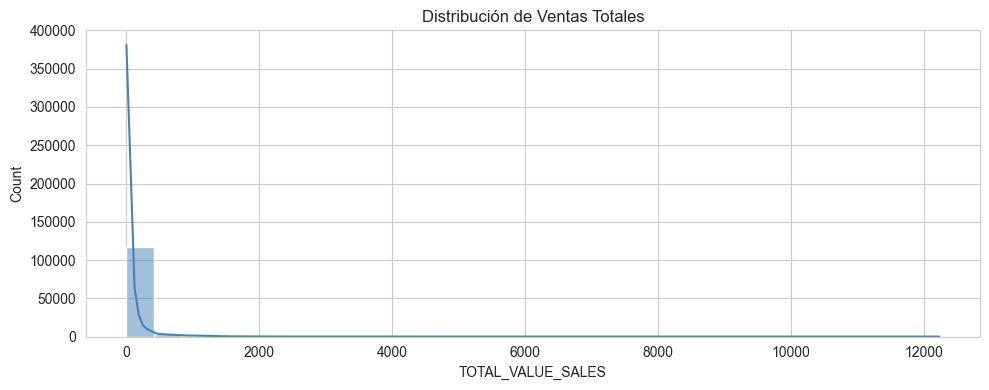

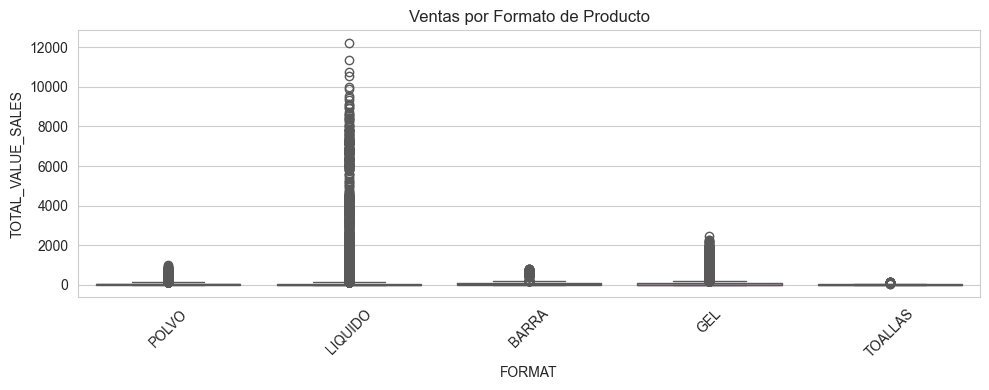

In [27]:
# Histograma de Ventas Totales (Entregable 2)
plt.figure(figsize=(10,4))
sns.histplot(data=df, x='TOTAL_VALUE_SALES', bins=30, kde=True, color='steelblue')
plt.title('Distribución de Ventas Totales')
plt.tight_layout(); plt.show()

# Boxplot por Formato
plt.figure(figsize=(10,4))
sns.boxplot(data=df, x='FORMAT', y='TOTAL_VALUE_SALES', palette='Set2')
plt.title('Ventas por Formato de Producto')
plt.xticks(rotation=45)
plt.tight_layout(); plt.show()

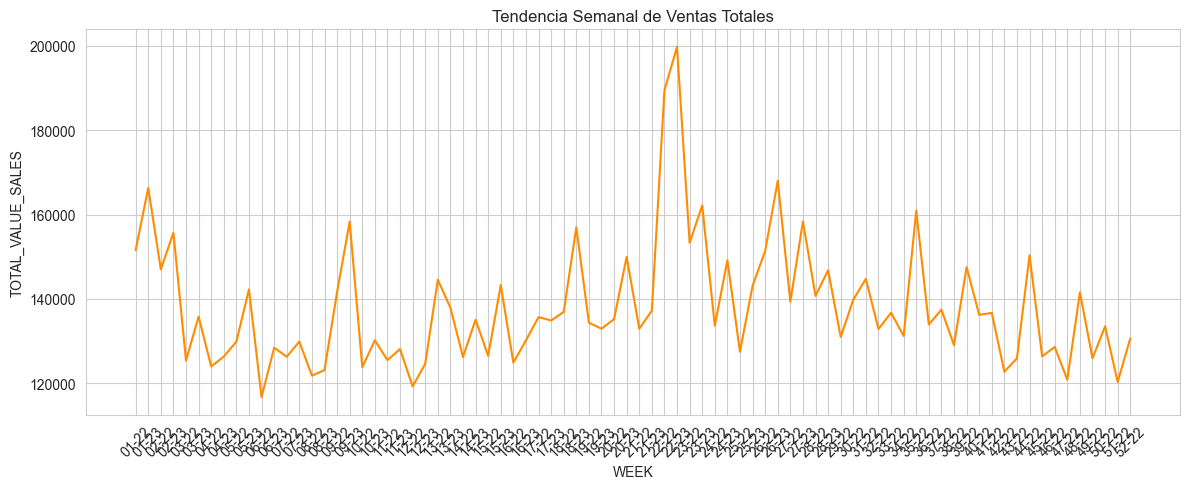

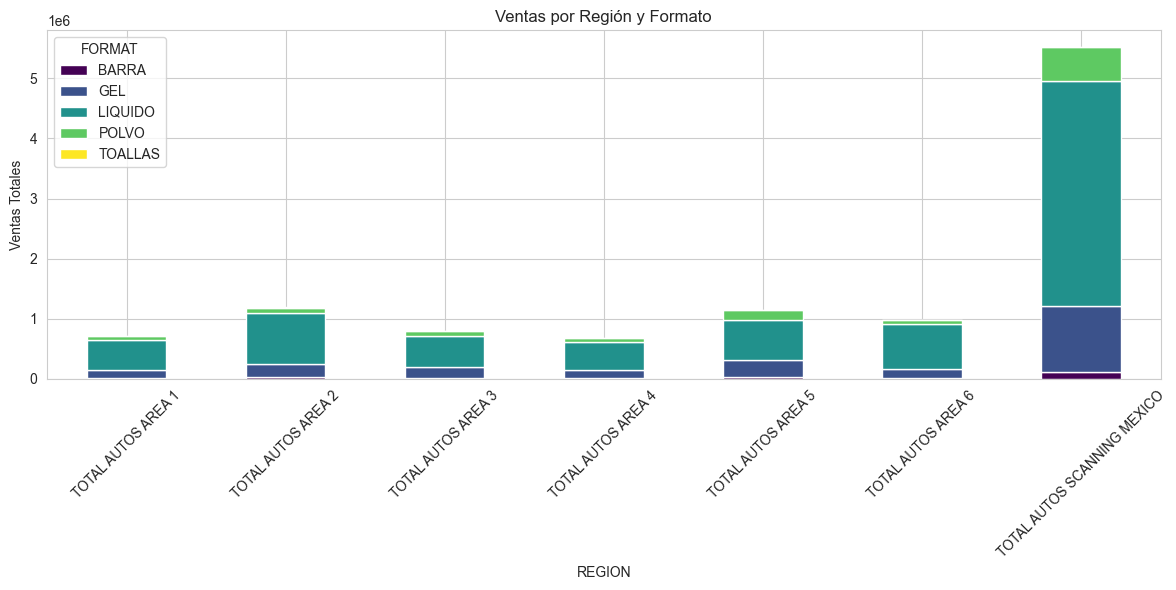

In [28]:
# Tendencia semanal
weekly_sales = df.groupby('WEEK')['TOTAL_VALUE_SALES'].sum().reset_index()
plt.figure(figsize=(12,5))
sns.lineplot(data=weekly_sales, x='WEEK', y='TOTAL_VALUE_SALES', color='darkorange')
plt.title('Tendencia Semanal de Ventas Totales')
plt.xticks(rotation=45)
plt.tight_layout(); plt.show()

# Ventas por Región y Formato
region_sales = df.groupby(['REGION', 'FORMAT'])['TOTAL_VALUE_SALES'].sum().unstack().fillna(0)
region_sales.plot(kind='bar', stacked=True, figsize=(12,6), colormap='viridis')
plt.title('Ventas por Región y Formato')
plt.ylabel('Ventas Totales')
plt.xticks(rotation=45)
plt.tight_layout(); plt.show()

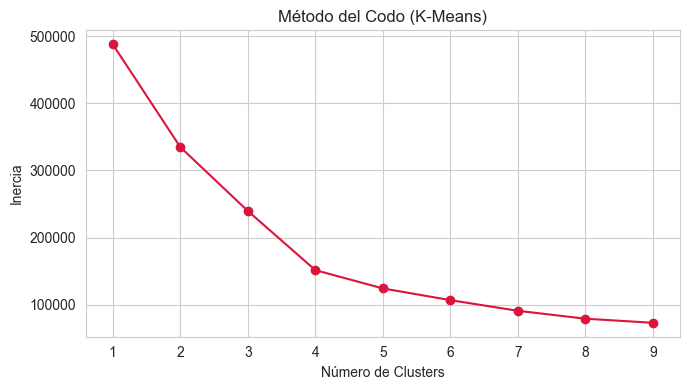

 Estadísticas por Clúster 
        TOTAL_UNIT_SALES          TOTAL_VALUE_SALES          
                    mean   median              mean    median
CLUSTER                                                      
0               2.411584    0.495         82.168038    21.570
1              39.370462   36.308        900.492127   906.864
2             248.404358  260.560       6005.599069  6235.981
3               1.165187    0.250         35.572088    12.120

Conteo por Clúster:
 CLUSTER
3    66609
0    51978
1     3155
2      260
Name: count, dtype: int64


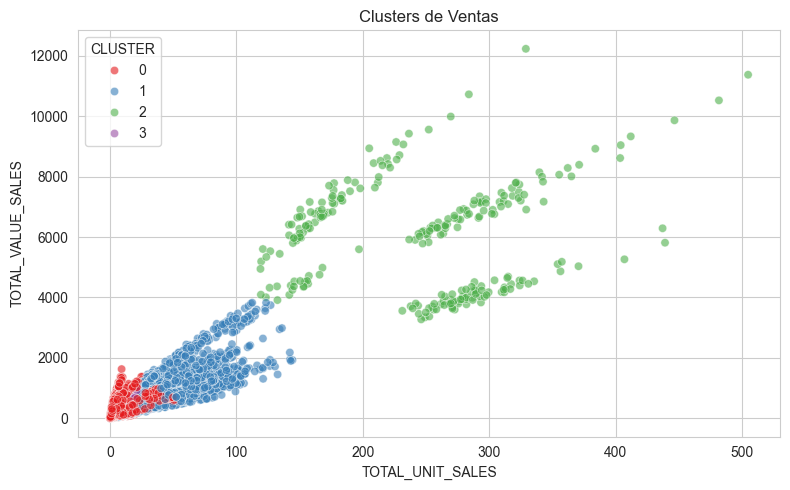

In [29]:
# Preparación de datos para Clustering (Entregable 3)
fact_cluster = df.copy()
fact_cluster["REGION"] = fact_cluster["REGION"].astype("category").cat.codes

features = fact_cluster[["TOTAL_UNIT_SALES", "TOTAL_VALUE_SALES", "TOTAL_UNIT_AVG_WEEKLY_SALES", "REGION"]].dropna()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

# Método del Codo
inertia = []
for k in range(1, 10):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(7,4))
plt.plot(range(1, 10), inertia, marker='o', color='crimson')
plt.title("Método del Codo (K-Means)")
plt.xlabel("Número de Clusters"); plt.ylabel("Inercia")
plt.tight_layout(); plt.show()

# Ajuste final con K=4
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
fact_cluster["CLUSTER"] = kmeans.fit_predict(X_scaled)

# Interpretación
print(" Estadísticas por Clúster ")
print(fact_cluster.groupby("CLUSTER")[["TOTAL_UNIT_SALES","TOTAL_VALUE_SALES"]].agg(["mean","median"]))
print("\nConteo por Clúster:\n", fact_cluster["CLUSTER"].value_counts())

# Scatter visual
plt.figure(figsize=(8,5))
sns.scatterplot(x="TOTAL_UNIT_SALES", y="TOTAL_VALUE_SALES", hue="CLUSTER",palette="Set1", data=fact_cluster, alpha=0.6)
plt.title("Clusters de Ventas")
plt.tight_layout(); 
plt.show()

In [33]:
marcas_objetivo = ["VANISH", "LYSOL"]
df_obj = df[df["BRAND_GRUPO"].isin(marcas_objetivo)].copy()

# OJO: usar los nombres reales de df (Semana, Año, Numero_Semana, Fecha)
serie_agg = (df_obj.groupby(["BRAND_GRUPO","Semana","Año","Numero_Semana","Fecha"], as_index=False)
             .agg(TOTAL_UNIT_SALES  = ("TOTAL_UNIT_SALES","sum"),
                  TOTAL_VALUE_SALES = ("TOTAL_VALUE_SALES","sum"),
                  N_ITEMS           = ("ITEM_CODE","nunique"),
                  N_REGIONES        = ("REGION","nunique"))
             .sort_values(["BRAND_GRUPO","Fecha"])
             .reset_index(drop=True))

for marca in marcas_objetivo:
    s = serie_agg[serie_agg["BRAND_GRUPO"] == marca]
    print(f"{marca}: {len(s)} semanas observadas | "
          f"{s['Fecha'].min().date()} → {s['Fecha'].max().date()}")

VANISH: 80 semanas observadas | 2022-01-09 → 2023-07-17
LYSOL: 80 semanas observadas | 2022-01-09 → 2023-07-17


In [34]:
series_modelo = {}
for marca in marcas_objetivo:
    s = (serie_agg[serie_agg["BRAND_GRUPO"] == marca]
         .set_index("Fecha")["TOTAL_UNIT_SALES"].sort_index())
    s = s.asfreq("7D")
    s = s.loc[:s.last_valid_index()]
    if s.isna().sum():
        s = s.interpolate(method="time").ffill().bfill()
    series_modelo[marca] = s
    print(f"{marca}: {len(s)} semanas, media={s.mean():.2f}, std={s.std():.2f}")

VANISH: 52 semanas, media=672.54, std=62.60
LYSOL: 52 semanas, media=7.29, std=3.39


In [35]:
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
import scipy.stats as stats

def test_estacionariedad(s, nombre):
    print(f"\n {nombre} ")
    adf_p = adfuller(s.dropna())[1]
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore")
        kpss_p = kpss(s.dropna(), regression='c', nlags='auto')[1]
    print(f"ADF  p-value = {adf_p:.4f}  → {'estacionaria' if adf_p < 0.05 else 'NO estacionaria'}")
    print(f"KPSS p-value = {kpss_p:.4f}  → {'estacionaria' if kpss_p >= 0.05 else 'NO estacionaria'}")
    adf_p_d1 = adfuller(s.diff().dropna())[1]
    print(f"ADF 1a dif  p = {adf_p_d1:.4f} → {'estacionaria' if adf_p_d1 < 0.05 else 'NO estacionaria'}")

for marca, s in series_modelo.items():
    test_estacionariedad(s, marca)


 VANISH 
ADF  p-value = 0.7864  → NO estacionaria
KPSS p-value = 0.0988  → estacionaria
ADF 1a dif  p = 0.0474 → estacionaria

 LYSOL 
ADF  p-value = 0.1635  → NO estacionaria
KPSS p-value = 0.1000  → estacionaria
ADF 1a dif  p = 0.0000 → estacionaria


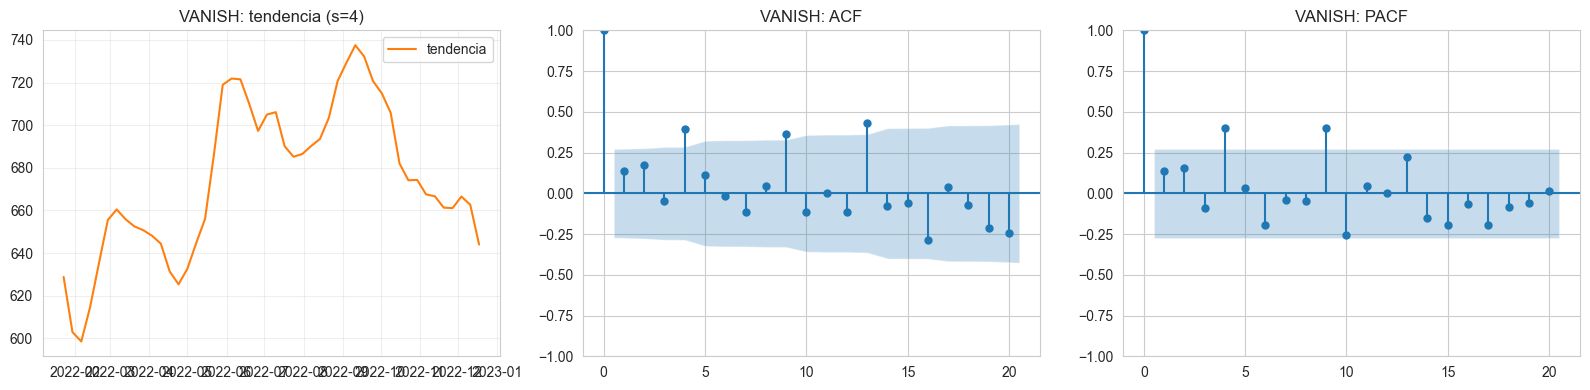

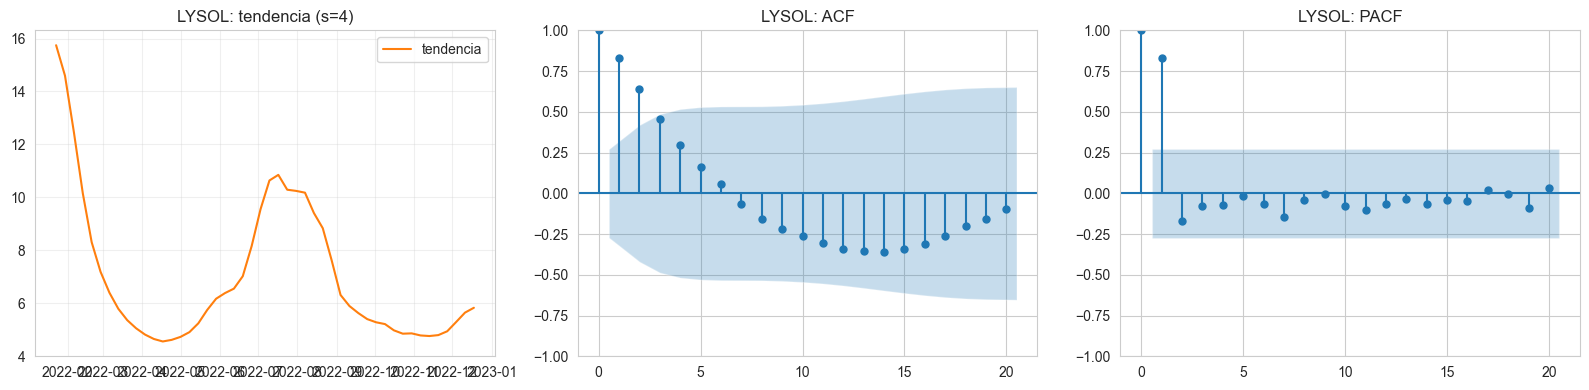

In [36]:
for marca, s in series_modelo.items():
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    dec = seasonal_decompose(s, model="additive", period=4)
    axes[0].plot(dec.trend, label="tendencia", color="C1")
    axes[0].set_title(f"{marca}: tendencia (s=4)")
    axes[0].legend(); axes[0].grid(alpha=.3)
    plot_acf(s, lags=20, ax=axes[1], title=f"{marca}: ACF")
    plot_pacf(s, lags=20, ax=axes[2], title=f"{marca}: PACF", method='ywm')
    plt.tight_layout(); plt.show()

In [37]:
def buscar_sarima(serie, s=4, max_p=2, max_d=2, max_q=2,
                  max_P=1, max_D=1, max_Q=1):
    best_aic = np.inf; best_model = None
    best_order = None; best_seasonal = None
    for p in range(max_p + 1):
        for d in range(max_d + 1):
            for q in range(max_q + 1):
                for P in range(max_P + 1):
                    for D in range(max_D + 1):
                        for Q in range(max_Q + 1):
                            if p == d == q == P == D == Q == 0:
                                continue
                            try:
                                with warnings.catch_warnings():
                                    warnings.filterwarnings("ignore")
                                    mod = SARIMAX(serie, order=(p,d,q),
                                                  seasonal_order=(P,D,Q,s),
                                                  enforce_stationarity=False,
                                                  enforce_invertibility=False).fit(disp=False)
                                if np.isfinite(mod.aic) and mod.aic < best_aic:
                                    best_aic = mod.aic; best_model = mod
                                    best_order = (p,d,q); best_seasonal = (P,D,Q,s)
                            except Exception:
                                continue
    return best_model, best_order, best_seasonal, best_aic

modelos_sarima = {}
for marca, s in series_modelo.items():
    print(f"\n--- {marca} ---")
    mod, order, seasonal, aic = buscar_sarima(
        s, s=4, max_p=2, max_d=1, max_q=2, max_P=1, max_D=1, max_Q=1)
    print(f"Mejor SARIMA: order={order}, seasonal={seasonal}, AIC={aic:.2f}")
    modelos_sarima[marca] = {"modelo": mod, "order": order,
                             "seasonal": seasonal, "aic": aic}


--- VANISH ---
Mejor SARIMA: order=(0, 1, 2), seasonal=(0, 1, 1, 4), AIC=457.21

--- LYSOL ---
Mejor SARIMA: order=(1, 0, 2), seasonal=(0, 1, 1, 4), AIC=168.42


In [38]:
def evaluar_variantes(serie_ts, variantes, n_test=10):
    train = serie_ts.iloc[:-n_test]; test = serie_ts.iloc[-n_test:]
    filas = []
    for v in variantes:
        try:
            with warnings.catch_warnings():
                warnings.filterwarnings("ignore")
                m_full  = SARIMAX(serie_ts, order=v["order"], seasonal_order=v["seasonal"],
                                  enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
                m_train = SARIMAX(train, order=v["order"], seasonal_order=v["seasonal"],
                                  enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
            lb_p = acorr_ljungbox(m_full.resid.dropna(), lags=[10], return_df=True)["lb_pvalue"].iloc[0]
            pred = m_train.forecast(steps=n_test); pred.index = test.index
            mae  = mean_absolute_error(test, pred)
            mape = np.mean(np.abs((test - pred) / test.clip(lower=1e-6))) * 100
            filas.append({"order": v["order"], "seasonal": v["seasonal"],
                          "AIC": m_full.aic, "BIC": m_full.bic,
                          "LjungBox_p": lb_p, "MAE_test": mae, "MAPE_test": mape,
                          "LjungBox_OK": lb_p > 0.05})
        except Exception:
            continue
    return pd.DataFrame(filas).sort_values("AIC").reset_index(drop=True)

variantes_lysol = [
    {"order": (1,0,2), "seasonal": (0,1,1,4)},
    {"order": (1,0,2), "seasonal": (0,0,0,0)},
    {"order": (2,0,2), "seasonal": (0,0,0,0)},
    {"order": (1,1,1), "seasonal": (0,0,0,0)},
    {"order": (2,1,1), "seasonal": (0,0,0,0)},
]
variantes_vanish = [
    {"order": (0,1,2), "seasonal": (0,1,1,4)},
    {"order": (0,1,1), "seasonal": (0,0,0,0)},
    {"order": (1,1,0), "seasonal": (0,0,0,0)},
    {"order": (1,1,1), "seasonal": (0,0,0,0)},
    {"order": (0,2,1), "seasonal": (0,0,0,0)},
]

print("Optimización Iterativa — LYSOL")
tabla_lysol = evaluar_variantes(series_modelo["LYSOL"], variantes_lysol, 10)
print(tabla_lysol.to_string())

print("\nOptimización Iterativa — VANISH")
tabla_vanish = evaluar_variantes(series_modelo["VANISH"], variantes_vanish, 10)
print(tabla_vanish.to_string())

def elegir_mejor(tabla):
    ok = tabla[tabla["LjungBox_OK"]]
    return (ok if len(ok) > 0 else tabla).sort_values("AIC").iloc[0]

mejor_lysol  = elegir_mejor(tabla_lysol)
mejor_vanish = elegir_mejor(tabla_vanish)

print("\nMejor Modelo")
print(f"LYSOL  - order={mejor_lysol['order']}, seasonal={mejor_lysol['seasonal']}, "
      f"AIC={mejor_lysol['AIC']:.2f}, LjungBox_p={mejor_lysol['LjungBox_p']:.4f}, "
      f"MAE_test={mejor_lysol['MAE_test']:.2f}")
print(f"VANISH - order={mejor_vanish['order']}, seasonal={mejor_vanish['seasonal']}, "
      f"AIC={mejor_vanish['AIC']:.2f}, LjungBox_p={mejor_vanish['LjungBox_p']:.4f}, "
      f"MAE_test={mejor_vanish['MAE_test']:.2f}")

Optimización Iterativa — LYSOL
       order      seasonal         AIC         BIC  LjungBox_p  MAE_test  MAPE_test  LjungBox_OK
0  (1, 0, 2)  (0, 1, 1, 4)  168.424432  176.992292    0.006704  0.766282  15.364675        False
1  (2, 1, 1)  (0, 0, 0, 0)  193.509218  201.076499    0.996952  0.551221  11.387817         True
2  (1, 0, 2)  (0, 0, 0, 0)  195.295637  202.862918    0.904649  2.206237  39.503363         True
3  (2, 0, 2)  (0, 0, 0, 0)  197.323278  206.782380    0.760415  2.195853  39.313139         True
4  (1, 1, 1)  (0, 0, 0, 0)  198.430073  204.105534    0.904591  0.747134  12.906493         True

Optimización Iterativa — VANISH
       order      seasonal         AIC         BIC  LjungBox_p   MAE_test  MAPE_test  LjungBox_OK
0  (0, 1, 2)  (0, 1, 1, 4)  457.214381  463.969899    0.348398  97.154979  15.643996         True
1  (0, 1, 1)  (0, 0, 0, 0)  546.313117  550.096758    0.963875  60.455648   9.527356         True
2  (1, 1, 1)  (0, 0, 0, 0)  547.889604  553.565065    0.9612

In [39]:
N_FUTURO = 8
futuro_idx = pd.date_range(series_modelo["VANISH"].index[-1] + pd.Timedelta(weeks=1),
                           periods=N_FUTURO, freq="7D")
print(f"\nPredicciones futuras ({futuro_idx[0].date()} → {futuro_idx[-1].date()}):")

resultados = {}
for marca, s in series_modelo.items():
    mejor = mejor_lysol if marca == "LYSOL" else mejor_vanish
    p, d, q       = mejor["order"]
    P, D, Q, s_per = mejor["seasonal"]

    with warnings.catch_warnings():
        warnings.filterwarnings("ignore")
        mod_full = SARIMAX(s, order=(p,d,q), seasonal_order=(P,D,Q,s_per),
                           enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)

    forecast  = mod_full.get_forecast(steps=N_FUTURO)
    pred_mean = forecast.predicted_mean.copy(); pred_mean.index = futuro_idx
    conf_int  = forecast.conf_int();           conf_int.index  = futuro_idx

    resultados[marca] = {
        "order_sarima": (p,d,q), "seasonal_sarima": (P,D,Q,s_per),
        "pred_futuro_sarima": pred_mean, "conf_int_sarima": conf_int,
        "ljungbox_p": mejor["LjungBox_p"],
        "mae_sarima": mejor["MAE_test"], "mape_sarima": mejor["MAPE_test"],
    }

    print(f"\n{marca} (SARIMA {p},{d},{q} x {P},{D},{Q},{s_per}):")
    print(pd.DataFrame({"pred":     pred_mean.round(2),
                        "ic_2.5%":  conf_int.iloc[:,0].round(2),
                        "ic_97.5%": conf_int.iloc[:,1].round(2)}).to_string())


Predicciones futuras (2023-01-08 → 2023-02-26):

VANISH (SARIMA 0,1,2 x 0,1,1,4):
              pred  ic_2.5%  ic_97.5%
2023-01-08  629.47   499.95    759.00
2023-01-15  644.27   514.27    774.28
2023-01-22  551.09   420.33    681.85
2023-01-29  639.29   507.78    770.79
2023-02-05  610.50   431.99    789.02
2023-02-12  625.61   445.59    805.62
2023-02-19  532.42   350.61    714.24
2023-02-26  620.62   437.02    804.21

LYSOL (SARIMA 2,1,1 x 0,0,0,0):
            pred  ic_2.5%  ic_97.5%
2023-01-08  6.28     3.23      9.34
2023-01-15  6.28     2.32     10.24
2023-01-22  6.27     1.84     10.71
2023-01-29  6.27     1.56     10.97
2023-02-05  6.26     1.39     11.14
2023-02-12  6.26     1.28     11.24
2023-02-19  6.26     1.21     11.31
2023-02-26  6.26     1.16     11.35


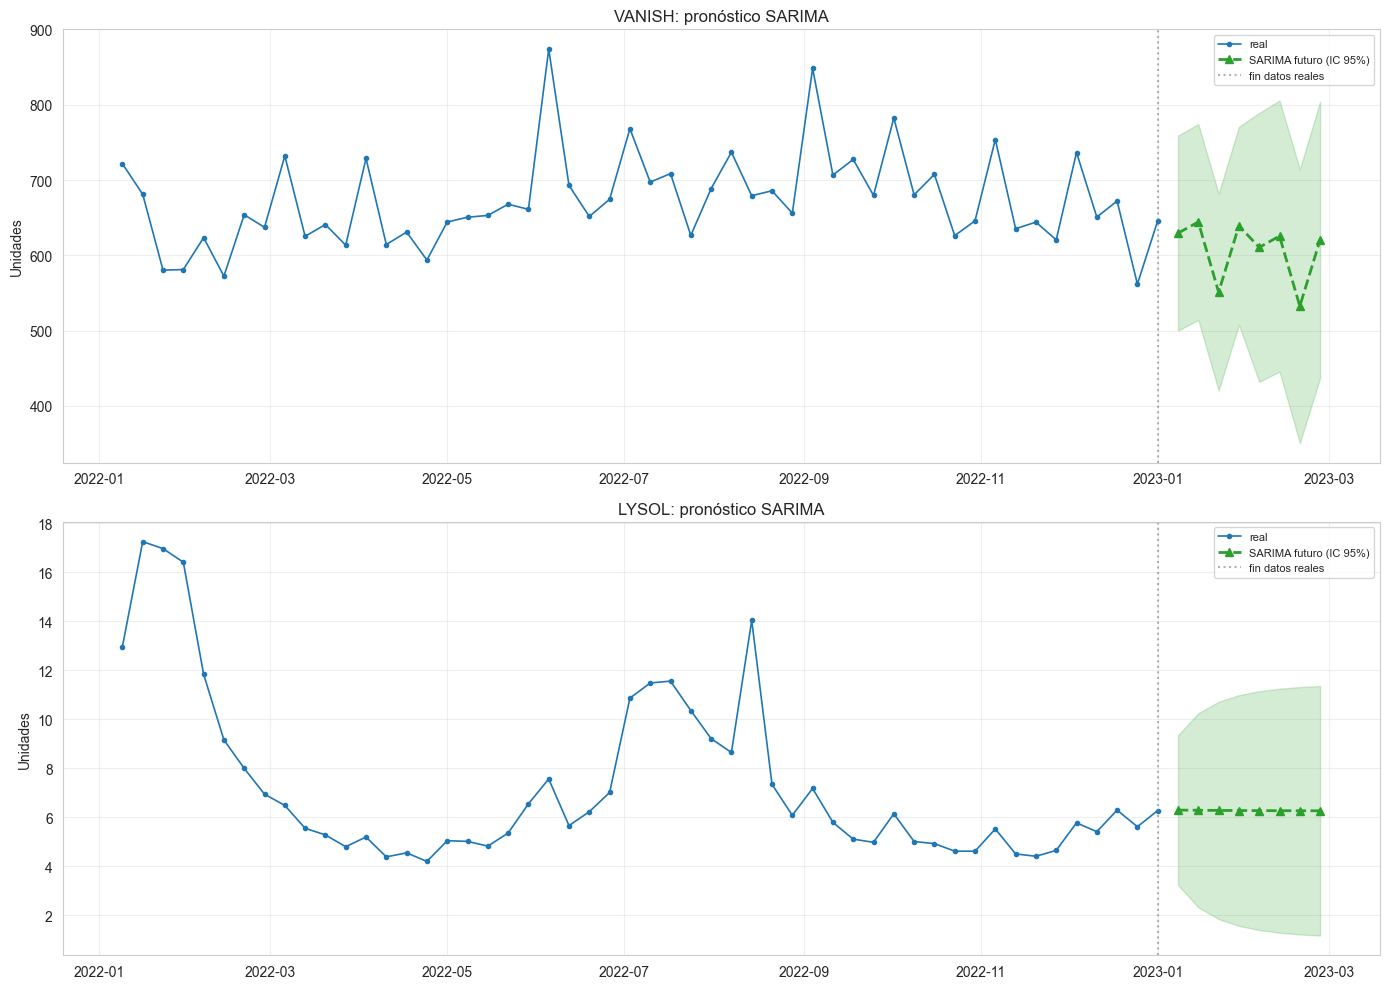

In [40]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=False)
for ax, (marca, r) in zip(axes, resultados.items()):
    s = series_modelo[marca]
    ax.plot(s.index, s.values, label="real", color="C0", marker="o", ms=3, lw=1.2)

    pf = r["pred_futuro_sarima"]; ci = r["conf_int_sarima"]
    ax.plot(pf.index, pf.values, label="SARIMA futuro (IC 95%)",
            color="C2", marker="^", ms=6, lw=2, ls="--")
    ax.fill_between(ci.index, ci.iloc[:,0], ci.iloc[:,1], color="C2", alpha=0.2)

    ax.axvline(s.index[-1], color="gray", ls=":", alpha=.6, label="fin datos reales")
    ax.set_title(f"{marca}: pronóstico SARIMA")
    ax.set_ylabel("Unidades"); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

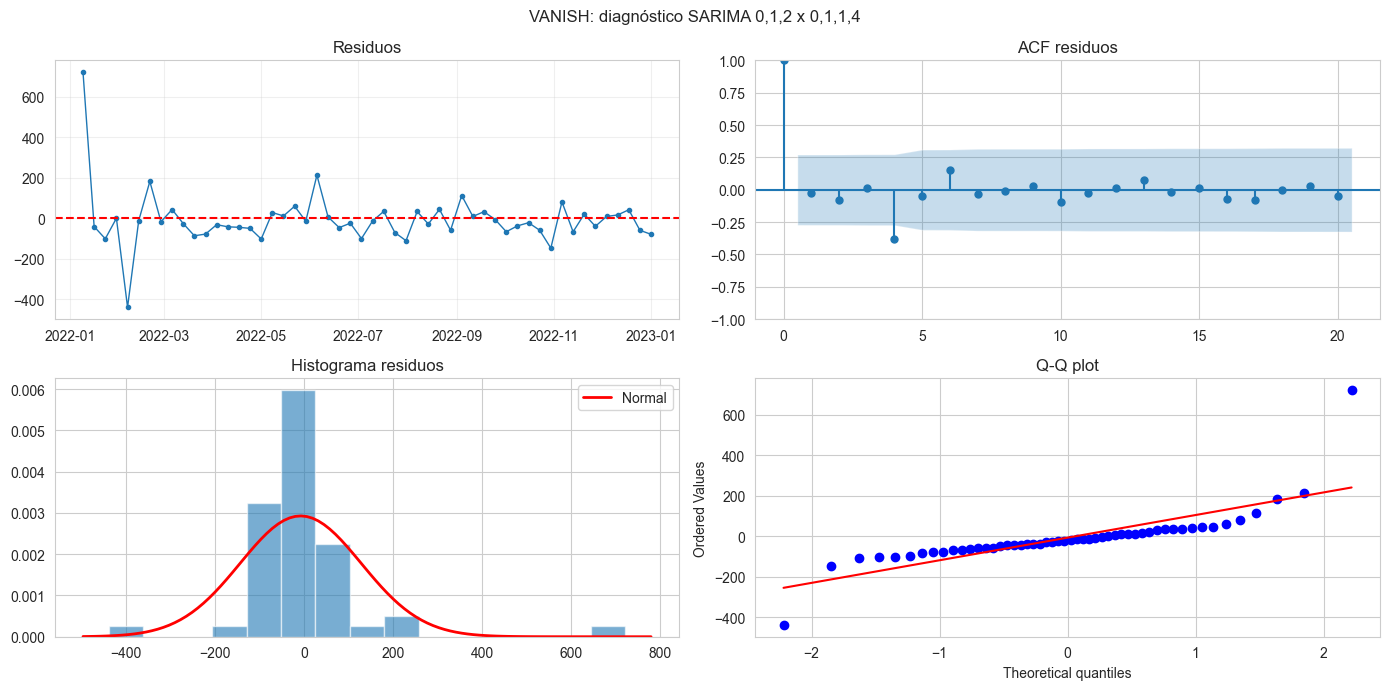

VANISH: Ljung-Box p (lag=10) = 0.3484 → residuos NO autocorrelacionados (OK)


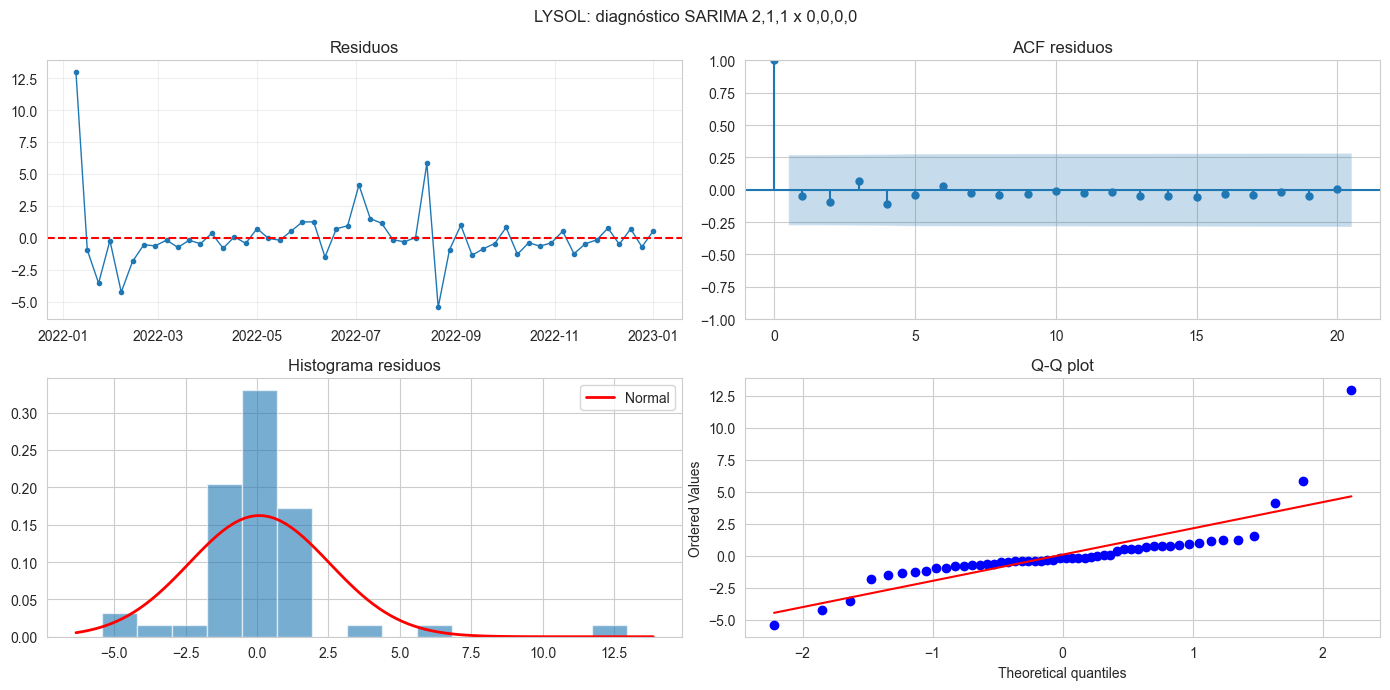

LYSOL: Ljung-Box p (lag=10) = 0.9970 → residuos NO autocorrelacionados (OK)

Resumen SARIMA
VANISH: order=(0, 1, 2), seasonal=(0, 1, 1, 4), LjungBox_p=0.3484, MAE_test=97.15, MAPE_test=15.64%, IC medio=311.43 (51.3% de la pred. media)
LYSOL: order=(2, 1, 1), seasonal=(0, 0, 0, 0), LjungBox_p=0.9970, MAE_test=0.55, MAPE_test=11.39%, IC medio=9.04 (144.2% de la pred. media)


In [41]:
for marca, r in resultados.items():
    p, d, q = r["order_sarima"]; P, D, Q, s_per = r["seasonal_sarima"]
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore")
        mod = SARIMAX(series_modelo[marca], order=(p,d,q), seasonal_order=(P,D,Q,s_per),
                      enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    resid = mod.resid
    fig, axes = plt.subplots(2, 2, figsize=(14, 7))
    fig.suptitle(f"{marca}: diagnóstico SARIMA {p},{d},{q} x {P},{D},{Q},{s_per}")
    axes[0,0].plot(resid.index, resid.values, marker="o", ms=3, lw=1)
    axes[0,0].axhline(0, color="red", ls="--"); axes[0,0].set_title("Residuos"); axes[0,0].grid(alpha=.3)
    plot_acf(resid.dropna(), lags=20, ax=axes[0,1], title="ACF residuos")
    axes[1,0].hist(resid.dropna(), bins=15, density=True, alpha=0.6, color="C0")
    xmin, xmax = axes[1,0].get_xlim(); xx = np.linspace(xmin, xmax, 100)
    axes[1,0].plot(xx, stats.norm.pdf(xx, resid.mean(), resid.std()), "r-", lw=2, label="Normal")
    axes[1,0].set_title("Histograma residuos"); axes[1,0].legend()
    stats.probplot(resid.dropna(), dist="norm", plot=axes[1,1]); axes[1,1].set_title("Q-Q plot")
    plt.tight_layout(); plt.show()
    lb = acorr_ljungbox(resid.dropna(), lags=[10], return_df=True)
    print(f"{marca}: Ljung-Box p (lag=10) = {lb['lb_pvalue'].iloc[0]:.4f} "
          f"→ {'residuos NO autocorrelacionados (OK)' if lb['lb_pvalue'].iloc[0] > 0.05 else 'revisar'}")

print("\nResumen SARIMA")
for marca, r in resultados.items():
    ci = r["conf_int_sarima"]; ancho = ci.iloc[:,1] - ci.iloc[:,0]
    print(f"{marca}: order={r['order_sarima']}, seasonal={r['seasonal_sarima']}, "
          f"LjungBox_p={r['ljungbox_p']:.4f}, "
          f"MAE_test={r['mae_sarima']:.2f}, MAPE_test={r['mape_sarima']:.2f}%, "
          f"IC medio={ancho.mean():.2f} "
          f"({ancho.mean()/r['pred_futuro_sarima'].mean()*100:.1f}% de la pred. media)")